# Enterprise Ransomware Risk Assessment Using NIST CSF 2.0

**Author:** Arya Anilkumar 

**Project type:** Cybersecurity risk assessment using a synthetic hypothetical dataset

## Project overview
This notebook demonstrates a simple, transparent risk assessment workflow for a fictional company, ABC Technologies Pvt. Ltd. It records hypothetical ransomware-related scenarios, calculates risk scores from likelihood and impact, assigns risk levels, displays charts, and exports the results to CSV.

**Important:** All risk records and scores in this notebook are illustrative and synthetic. They are not real incident data, measured probabilities, or the result of auditing a real organization. The risk thresholds are project-defined and are not official NIST-mandated thresholds.

## Risk scoring method
- Risk score = Likelihood × Impact
- Likelihood and impact are each scored from 1 to 5.
- 1–4: Low; 5–9: Moderate; 10–16: High; 17–25: Critical.

The recommendations are mapped at a high level to the six NIST Cybersecurity Framework (CSF) 2.0 functions: Govern, Identify, Protect, Detect, Respond, and Recover.


In [1]:
# Cell 1: Import required libraries
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully.")


Libraries imported successfully.


## 1. Create the synthetic dataset

The dataset below is created directly in the notebook. No external dataset download is required, so the project can run offline after its Python dependencies are installed.

In [2]:
# Cell 2: Define hypothetical ransomware risk scenarios
risk_records = [
    {
        "Risk_ID": "R01",
        "Asset": "Employee email and computers",
        "Scenario": "Employee opens a malicious email attachment",
        "Vulnerability": "Limited phishing awareness and email filtering",
        "Likelihood": 4,
        "Impact": 5,
        "NIST_CSF_Function": "Protect",
        "Mitigation": "Provide phishing awareness training and strengthen email filtering."
    },
    {
        "Risk_ID": "R02",
        "Asset": "User accounts",
        "Scenario": "An attacker compromises an account with weak authentication",
        "Vulnerability": "MFA is not consistently enabled",
        "Likelihood": 4,
        "Impact": 5,
        "NIST_CSF_Function": "Protect",
        "Mitigation": "Enforce MFA, unique passwords, and least-privilege access."
    },
    {
        "Risk_ID": "R03",
        "Asset": "Employee computers and servers",
        "Scenario": "Ransomware exploits an unpatched software vulnerability",
        "Vulnerability": "Security updates are delayed",
        "Likelihood": 3,
        "Impact": 5,
        "NIST_CSF_Function": "Protect",
        "Mitigation": "Maintain an asset inventory and apply security patches promptly."
    },
    {
        "Risk_ID": "R04",
        "Asset": "Central file server",
        "Scenario": "Business files become unavailable after a ransomware incident",
        "Vulnerability": "Broad file-share permissions and limited segmentation",
        "Likelihood": 3,
        "Impact": 5,
        "NIST_CSF_Function": "Identify",
        "Mitigation": "Review permissions, apply least privilege, and segment critical systems."
    },
    {
        "Risk_ID": "R05",
        "Asset": "Backup repository",
        "Scenario": "Backups cannot be restored when needed",
        "Vulnerability": "Backup restoration is not tested regularly",
        "Likelihood": 3,
        "Impact": 5,
        "NIST_CSF_Function": "Recover",
        "Mitigation": "Maintain protected, isolated backups and test restoration regularly."
    },
    {
        "Risk_ID": "R06",
        "Asset": "Cloud storage",
        "Scenario": "Unauthorized access exposes or disrupts stored business data",
        "Vulnerability": "Cloud permissions may be overly broad",
        "Likelihood": 3,
        "Impact": 4,
        "NIST_CSF_Function": "Protect",
        "Mitigation": "Review cloud permissions, enable MFA, and monitor access."
    },
    {
        "Risk_ID": "R07",
        "Asset": "Endpoints and security logs",
        "Scenario": "Suspicious endpoint activity is not detected promptly",
        "Vulnerability": "Limited centralized logging and alerting",
        "Likelihood": 3,
        "Impact": 4,
        "NIST_CSF_Function": "Detect",
        "Mitigation": "Centralize relevant logs and configure alerts for suspicious activity."
    },
    {
        "Risk_ID": "R08",
        "Asset": "Business operations",
        "Scenario": "Recovery is delayed because response roles are unclear",
        "Vulnerability": "No documented and tested incident response plan",
        "Likelihood": 4,
        "Impact": 4,
        "NIST_CSF_Function": "Respond",
        "Mitigation": "Document response responsibilities and rehearse incident procedures."
    },
]

df = pd.DataFrame(risk_records)
print(f"Created {len(df)} synthetic risk records.")
display(df)


Created 8 synthetic risk records.


,Risk_ID,Asset,Scenario,Vulnerability,Likelihood,Impact,NIST_CSF_Function,Mitigation
0,R01,Employee email and computers,Employee opens a malicious email attachment,Limited phishing awareness and email filtering,4,5,Protect,Provide phishing awareness training and streng...
1,R02,User accounts,An attacker compromises an account with weak a...,MFA is not consistently enabled,4,5,Protect,"Enforce MFA, unique passwords, and least-privi..."
2,R03,Employee computers and servers,Ransomware exploits an unpatched software vuln...,Security updates are delayed,3,5,Protect,Maintain an asset inventory and apply security...
3,R04,Central file server,Business files become unavailable after a rans...,Broad file-share permissions and limited segme...,3,5,Identify,"Review permissions, apply least privilege, and..."
4,R05,Backup repository,Backups cannot be restored when needed,Backup restoration is not tested regularly,3,5,Recover,"Maintain protected, isolated backups and test ..."
5,R06,Cloud storage,Unauthorized access exposes or disrupts stored...,Cloud permissions may be overly broad,3,4,Protect,"Review cloud permissions, enable MFA, and moni..."
6,R07,Endpoints and security logs,Suspicious endpoint activity is not detected p...,Limited centralized logging and alerting,3,4,Detect,Centralize relevant logs and configure alerts ...
7,R08,Business operations,Recovery is delayed because response roles are...,No documented and tested incident response plan,4,4,Respond,Document response responsibilities and rehears...


## 2. Validate the input data

Likelihood and impact must be whole-number scores between 1 and 5. This check helps catch invalid data before calculating risk levels.

In [3]:
# Cell 3: Validate likelihood and impact scores
for column in ["Likelihood", "Impact"]:
    if not df[column].between(1, 5).all():
        raise ValueError(f"Every {column} value must be between 1 and 5.")
    if not pd.api.types.is_integer_dtype(df[column]):
        raise TypeError(f"{column} values must be integers.")

if df["Risk_ID"].duplicated().any():
    raise ValueError("Risk_ID values must be unique.")

print("Validation passed: scores are in range and risk IDs are unique.")


Validation passed: scores are in range and risk IDs are unique.


## 3. Calculate scores and assign risk levels

The classification thresholds are chosen for this educational project:
- **Low:** 1–4
- **Moderate:** 5–9
- **High:** 10–16
- **Critical:** 17–25

These thresholds are a project-specific scoring convention, not an official NIST requirement.

In [4]:
# Cell 4: Calculate risk scores and classifications
def classify_risk(score):
    if score >= 17:
        return "Critical"
    if score >= 10:
        return "High"
    if score >= 5:
        return "Moderate"
    return "Low"

df["Risk_Score"] = df["Likelihood"] * df["Impact"]
df["Risk_Level"] = df["Risk_Score"].apply(classify_risk)

# Sort highest risks first for easier review
df = df.sort_values(["Risk_Score", "Risk_ID"], ascending=[False, True]).reset_index(drop=True)

display(df[[
    "Risk_ID", "Asset", "Scenario", "Likelihood", "Impact",
    "Risk_Score", "Risk_Level", "NIST_CSF_Function", "Mitigation"
]])


,Risk_ID,Asset,Scenario,Likelihood,Impact,Risk_Score,Risk_Level,NIST_CSF_Function,Mitigation
0,R01,Employee email and computers,Employee opens a malicious email attachment,4,5,20,Critical,Protect,Provide phishing awareness training and streng...
1,R02,User accounts,An attacker compromises an account with weak a...,4,5,20,Critical,Protect,"Enforce MFA, unique passwords, and least-privi..."
2,R08,Business operations,Recovery is delayed because response roles are...,4,4,16,High,Respond,Document response responsibilities and rehears...
3,R03,Employee computers and servers,Ransomware exploits an unpatched software vuln...,3,5,15,High,Protect,Maintain an asset inventory and apply security...
4,R04,Central file server,Business files become unavailable after a rans...,3,5,15,High,Identify,"Review permissions, apply least privilege, and..."
5,R05,Backup repository,Backups cannot be restored when needed,3,5,15,High,Recover,"Maintain protected, isolated backups and test ..."
6,R06,Cloud storage,Unauthorized access exposes or disrupts stored...,3,4,12,High,Protect,"Review cloud permissions, enable MFA, and moni..."
7,R07,Endpoints and security logs,Suspicious endpoint activity is not detected p...,3,4,12,High,Detect,Centralize relevant logs and configure alerts ...


## 4. Summarize risk distribution

The following chart counts how many hypothetical risks fall into each risk category. It describes this sample only and should not be interpreted as a statistical estimate of real-world ransomware risk.

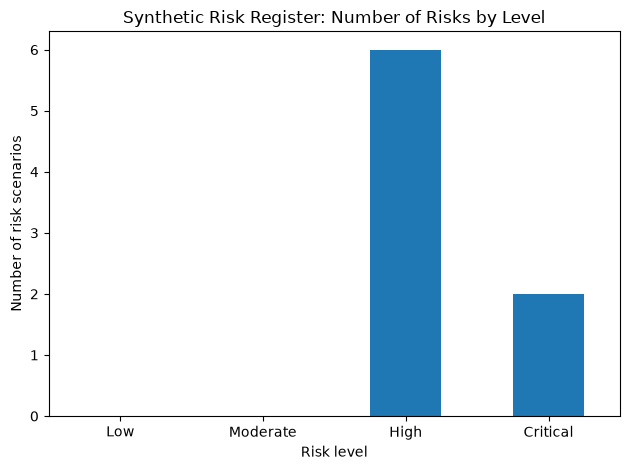

,Number_of_Risks
Risk_Level,
Low,0
Moderate,0
High,6
Critical,2


In [5]:
# Cell 5: Plot risk-level distribution
risk_order = ["Low", "Moderate", "High", "Critical"]
risk_counts = df["Risk_Level"].value_counts().reindex(risk_order, fill_value=0)

ax = risk_counts.plot(kind="bar", rot=0)
ax.set_title("Synthetic Risk Register: Number of Risks by Level")
ax.set_xlabel("Risk level")
ax.set_ylabel("Number of risk scenarios")
plt.tight_layout()
plt.show()

display(risk_counts.rename("Number_of_Risks").to_frame())


## 5. Create a likelihood-impact matrix

Each cell in the matrix counts the number of scenarios with a particular likelihood and impact score. The numbers are based on the synthetic records above.

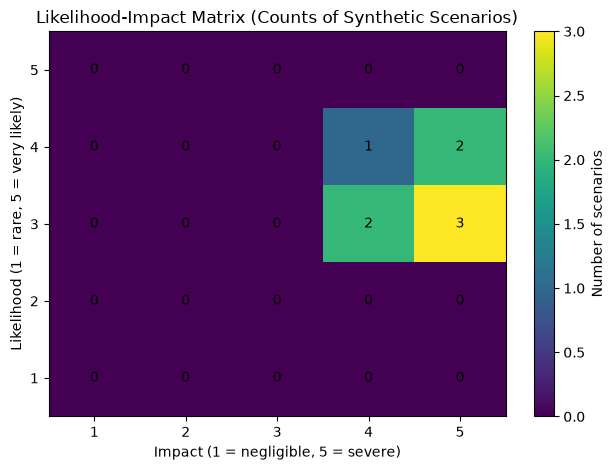

Impact,1,2,3,4,5
Likelihood,,,,,
1,0,0,0,0,0
2,0,0,0,0,0
3,0,0,0,2,3
4,0,0,0,1,2
5,0,0,0,0,0


In [6]:
# Cell 6: Plot a 5x5 likelihood-impact matrix
matrix = pd.crosstab(df["Likelihood"], df["Impact"]).reindex(
    index=range(1, 6), columns=range(1, 6), fill_value=0
)

fig, ax = plt.subplots()
image = ax.imshow(matrix.values, origin="lower", aspect="auto")
ax.set_xticks(range(5), labels=range(1, 6))
ax.set_yticks(range(5), labels=range(1, 6))
ax.set_xlabel("Impact (1 = negligible, 5 = severe)")
ax.set_ylabel("Likelihood (1 = rare, 5 = very likely)")
ax.set_title("Likelihood-Impact Matrix (Counts of Synthetic Scenarios)")

for i in range(5):
    for j in range(5):
        ax.text(j, i, str(matrix.iloc[i, j]), ha="center", va="center")

fig.colorbar(image, ax=ax, label="Number of scenarios")
plt.tight_layout()
plt.show()

display(matrix)


## 6. Generate a concise findings summary

This section summarizes the highest-scoring risks and provides a count by NIST CSF function. The output is a planning aid, not a substitute for review by a qualified security professional.

In [7]:
# Cell 7: Summarize findings
highest_score = int(df["Risk_Score"].max())
highest_risks = df.loc[df["Risk_Score"] == highest_score, ["Risk_ID", "Scenario", "Risk_Score"]]

print(f"Total hypothetical risk scenarios: {len(df)}")
print(f"Highest risk score in this sample: {highest_score}/25")
print("\nRisk counts by level:")
print(risk_counts.to_string())

print("\nHighest-scoring scenarios:")
display(highest_risks)

print("\nRisk scenarios by NIST CSF function:")
display(df.groupby("NIST_CSF_Function").size().rename("Count").to_frame())


Total hypothetical risk scenarios: 8
Highest risk score in this sample: 20/25

Risk counts by level:
Risk_Level
Low         0
Moderate    0
High        6
Critical    2

Highest-scoring scenarios:


,Risk_ID,Scenario,Risk_Score
0,R01,Employee opens a malicious email attachment,20
1,R02,An attacker compromises an account with weak a...,20



Risk scenarios by NIST CSF function:


,Count
NIST_CSF_Function,
Detect,1
Identify,1
Protect,4
Recover,1
Respond,1


## 7. Export the risk register

The notebook writes the calculated results to `ransomware_risk_assessment_results.csv` in the current working directory. The CSV contains the synthetic input scenarios and calculated risk scores.

In [8]:
# Cell 8: Export results to CSV
output_file = Path("ransomware_risk_assessment_results.csv")
df.to_csv(output_file, index=False)

print(f"Risk register exported to: {output_file.resolve()}")
print(f"Rows exported: {len(df)}")


Risk register exported to: /home/user/Desktop/ML/ransomware_risk_assessment_results.csv
Rows exported: 8


## 8. Conclusion

This demonstration shows how a structured risk register can help an organization document and prioritize hypothetical ransomware-related scenarios. The sample identifies backups, authentication, phishing exposure, software patching, monitoring, and incident response readiness as areas worth reviewing.

The recommended next steps for a real organization would be to validate the assumptions with asset owners, assess existing controls and evidence, agree on risk tolerance, assign accountable owners and due dates, and periodically test backup restoration and incident response procedures.

## Limitations
- The dataset is synthetic and contains only eight illustrative scenarios.
- Likelihood and impact values are assumptions for demonstration; they are not measured probabilities.
- Risk thresholds are defined for this project and are not mandated by NIST.
- The notebook does not detect ransomware, scan systems, or audit a live environment.
- NIST CSF mapping is high-level. A real assessment should map recommendations to relevant CSF 2.0 categories and organizational requirements.

## References
1. NIST, *Ransomware Risk Management: A Cybersecurity Framework 2.0 Community Profile*, NIST IR 8374 Rev. 1: https://csrc.nist.gov/pubs/ir/8374/r1/final
2. NIST Cybersecurity Framework: https://www.nist.gov/cyberframework
3. CISA, *StopRansomware Guide*: https://www.cisa.gov/stopransomware/ransomware-guide
